In [1]:
# ! means that it runs through terminal
!pip install zerosyl

!pip install tgt

# wget downloads things directly from the internet
!wget https://storage.googleapis.com/zerospeech-checkpoints/5895-34629-0010.flac
!wget https://storage.googleapis.com/zerospeech-checkpoints/5895-34629-0010.TextGrid

--2026-08-05 11:11:17--  https://storage.googleapis.com/zerospeech-checkpoints/5895-34629-0010.flac
Resolving storage.googleapis.com (storage.googleapis.com)... 142.251.47.251, 192.178.54.123, 172.217.170.155, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|142.251.47.251|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 44534 (43K) [audio/flac]
Saving to: ‘5895-34629-0010.flac.6’

5895-34629-0010.fla 100%[===================>]  43.49K   105KB/s    in 0.4s    

2026-08-05 11:11:21 (105 KB/s) - ‘5895-34629-0010.flac.6’ saved [44534/44534]

--2026-08-05 11:11:21--  https://storage.googleapis.com/zerospeech-checkpoints/5895-34629-0010.TextGrid
Resolving storage.googleapis.com (storage.googleapis.com)... 172.217.170.155, 192.178.54.187, 142.251.47.27, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|172.217.170.155|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2880 (2.8K) [application/octet-stream]
Savin

In [2]:
# import all relevant functions and or libraries
import matplotlib.pyplot as plt
import numpy as np
import tgt
import torch
import torchaudio
from IPython.display import Audio, display
from scipy.cluster.hierarchy import cut_tree, linkage
from scipy.signal import find_peaks

from zerosyl import WavLM

plt.rcParams["font.family"] = "monospace"

In [3]:

# create an instance of wavlm model with pretrained weights gotten from "remote"
wavlm = WavLM.from_remote()



In [4]:
# wav contains the audio data, where as sr contains the sample rate of the audio (hz)
wav, sr = torchaudio.load("id_82_main_post_test.wav")
# here we can see that sr matches the rate we display the audio at (16000 hz)
print(f"Original sample rate: {sr}")
display(Audio(wav, rate=16000))

Original sample rate: 16000


In [5]:
# preprocessing of the waveform
# loudness normalization
wav = torch.nn.functional.layer_norm(wav, wav.shape) # this ensures that one audio recording with very loud audio and another one with soft audio are both normalized to be the same aduio
# zero-pad such that the output features will be perfectly aligned with 20ms intervals
wav = torch.nn.functional.pad(wav, ((400 - 320) // 2, (400 - 320) // 2))

In [6]:
#Extract boundary features from layer 13
# the model has x amount of layers, at the 13th layer, we extract the feature vectors and look at what is going on in them 
# note how we are doing it for our audio sampe wav, so the features we extract will be unique to wav
with torch.inference_mode():
    boundary_features, _ = wavlm.extract_features(wav, output_layer=13)

# some kind of normalization or reduction technique

#numpy turns py torch tensor to numpy array. Changes data format, makes it easier to work with
#squeeze(0) removes the 0th dimension
    #Original shape: [1, time_steps, feature_dim]
    #After squeeze: [time_steps, feature_dim]
boundary_features = boundary_features.squeeze(0).cpu().numpy()

#display how many/ dimensionality of vectors [time_steps/ frames = 108, feature_dim = 1024]
# note feature dimension depends on lm model used, since we use wavLM large, it will alwys be 1024
boundary_features.shape

(3727, 1024)

In [7]:
#Perform boundary detection using peak detection on smoothed L2 norms

# compute the L2 norm signal
norms = np.linalg.norm(boundary_features, axis=-1)
#print(norms) gives you 108 distances, i.e. the magnitudes of the vectors
# normalize the norm signal
norms = (norms - norms.mean()) / norms.std()
# takes those magniturdes and normalises them so that they are centered around 0


# smooth the L2 norm signal
kernel = np.ones(3) / 3 # kernal is moving average, takes average of 3 neigbouring values
pad_len = 3 // 2 # pad_len adds one value on each side of norms vector, both on start and finish, adding 2 in total
norms_padded = np.pad(norms, (pad_len, pad_len), mode="edge") # adds padding to norms, makes smoothing possible
norms_smooth = np.convolve(norms_padded, kernel, mode="valid") # averages out values so that you get less jaggedness

# why smooth?
#Removes high-frequency noise
#Emphasizes meaningful acoustic changes
#Reduces false positives in peak detection

# performan prominence based peak detection
peaks, _ = find_peaks(norms_smooth, prominence=0.45)
# 0.45 is the minimum height relative to surrounding valeys for a peak to be detected
print(peaks)

# use peaks to detemine boundaries
boundaries = [0] + peaks.tolist() + [len(boundary_features)] # very simply adding start and finish to boundraries
print(boundaries)

[  21   33   40   55   66   77   87   95  110  122  132  139  146  157
  165  184  197  216  231  249  257  266  274  294  305  317  325  336
  343  351  363  377  382  388  399  416  427  444  460  487  495  504
  515  522  541  550  559  568  575  581  604  613  618  636  648  669
  677  690  707  714  726  735  762  785  798  807  820  826  838  853
  873  895  904  914  927  946  963  972  993 1008 1020 1037 1047 1056
 1079 1093 1098 1109 1118 1127 1137 1151 1160 1170 1186 1198 1206 1233
 1244 1256 1267 1276 1287 1294 1303 1316 1368 1379 1391 1407 1433 1440
 1447 1455 1464 1477 1487 1501 1510 1520 1532 1548 1557 1568 1576 1589
 1603 1617 1631 1642 1662 1675 1682 1695 1705 1728 1736 1751 1767 1779
 1790 1805 1812 1817 1826 1837 1843 1862 1874 1882 1891 1897 1901 1911
 1917 1926 1933 1950 1968 1975 1985 1998 2008 2036 2050 2061 2071 2086
 2095 2107 2123 2135 2150 2158 2163 2178 2186 2196 2204 2210 2223 2246
 2256 2261 2272 2278 2286 2304 2317 2330 2339 2349 2358 2368 2388 2410
 2428 

In [8]:


textgrid = tgt.read_textgrid("id_5_main_post_test_syllables.TextGrid")
# textgrid = None



In [9]:
# compute mel spectrogram
tMel = torchaudio.transforms.MelSpectrogram(
    n_fft=1024,
    win_length=400,
    hop_length=320,
)
tDB = torchaudio.transforms.AmplitudeToDB(top_db=80) #log scale: changes its scale to better match human perception (higher frequencies are harder to distinguish for humans than lower ones)

melspec = tDB(tMel(wav.squeeze()))

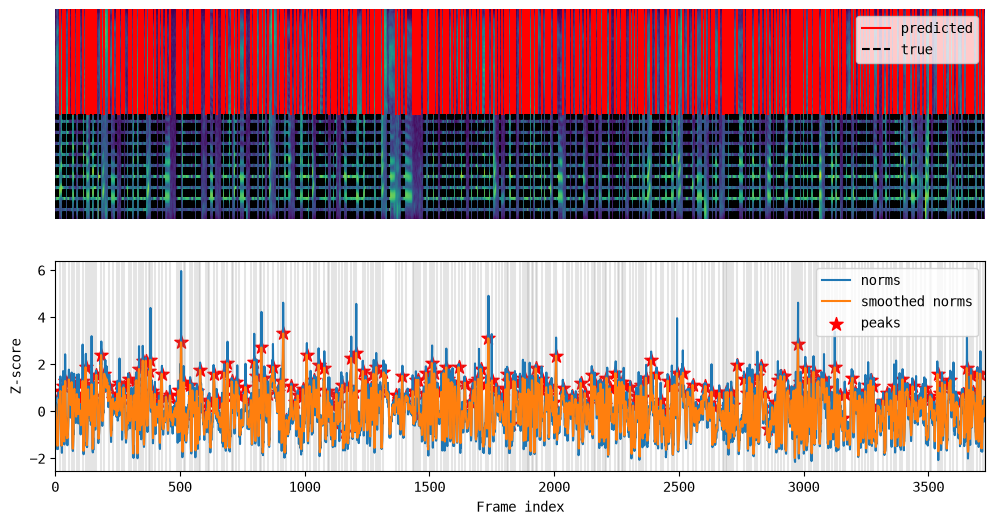

In [14]:


xmin, xmax = 0, melspec.size(1)

plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.imshow(melspec, aspect="auto", origin="lower")
plt.axis("off")
for i, b in enumerate(peaks):
    plt.axvline(b, ymin=0.5, c="r", label="predicted" if i == 0 else None)

if not textgrid is None:
    for i, interval in enumerate(textgrid.get_tier_by_name("syllables")):
        x1 = interval.start_time * 50
        x2 = interval.end_time * 50
        plt.axvline(
            x1, ymax=0.5, c="k", linestyle="--", label="true" if i == 0 else None
        )
        plt.axvline(x2, ymax=0.5, c="k", linestyle="--")
plt.xlim(xmin, xmax)
plt.legend()

plt.subplot(2, 1, 2)
for b in boundaries:
    plt.axvline(b, c="gray", alpha=0.2)

peaks_x = peaks
peaks_y = norms_smooth[peaks_x]

plt.plot(norms, label="norms")
plt.plot(norms_smooth, label="smoothed norms")
plt.scatter(peaks_x, peaks_y, marker="*", label="peaks", color="red", s=100)
plt.xlim(xmin, xmax)
plt.xlabel("Frame index")
plt.ylabel("Z-score")
plt.legend()




In [11]:


listen_samples = []
listen_samples.append(np.zeros(8000))
for start_frame, end_frame in zip(boundaries[:-1], boundaries[1:]):
    listen_samples.append(wav[0, start_frame * 320 : end_frame * 320])
    listen_samples.append(np.zeros(8000))
listen_samples = np.concat(listen_samples, axis=0)
display(Audio(listen_samples, rate=16000))



In [15]:
# now extract semantic features from higher layer (22)
# what is a semantic? it is meaning, low is fact, higher is meaning
with torch.inference_mode():
    semantic_features, _ = wavlm.extract_features(wav, output_layer=22)

semantic_features = semantic_features.squeeze(0)

semantic_features.shape

torch.Size([3727, 1024])

In [16]:
starts = torch.tensor(boundaries[:-1], device=wav.device)
ends = torch.tensor(boundaries[1:], device=wav.device)
embeddings = [
    semantic_features[start:end].mean(dim=0) for start, end in zip(starts, ends)
]
embeddings = torch.stack(embeddings)

In [17]:
embeddings.shape

torch.Size([297, 1024])

In [18]:


# Load the K-Means centroids
centroids = torch.hub.load_state_dict_from_url(
    "https://storage.googleapis.com/zerospeech-checkpoints/zerosyl-v040-centroids-k-10000.pt"
)
# Find the ID of the nearest centroid
ids = torch.cdist(embeddings.cpu(), centroids).argmin(1)



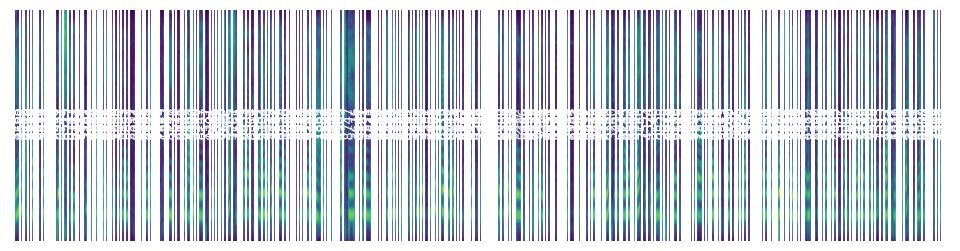

In [19]:
plt.figure(figsize=(12, 3))
plt.subplot(1, 1, 1)
plt.imshow(melspec, aspect="auto", origin="lower")
plt.axis("off")
for b1, b2, id in zip(boundaries[:-1], boundaries[1:], ids):
    plt.axvline(b1, c="w")
    plt.axvline(b2, c="w")
    plt.text(
        (b1 + b2) / 2, 64, str(id.item()), rotation=90, c="w", ha="center", va="center"
    )


In [20]:


# agglomerative clustering
linkage_matrix = linkage(
    centroids.numpy(), method="ward", metric="euclidean", optimal_ordering=False
)
# cut dendrogram into 2 main branches
silences = cut_tree(linkage_matrix, 2)[:, 0]
# the smaller branch should be silences
if silences.sum() > (1 - silences).sum():
    silences = 1 - silences
# to torch tensor
silences = torch.from_numpy(silences).bool()



In [21]:
print(silences[ids])

tensor([False, False, False, False, False, False, False,  True,  True, False,
        False, False, False, False, False, False, False, False, False, False,
         True,  True, False, False, False, False, False, False, False, False,
        False, False, False,  True, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
         True,  True, False, False, False,  True, False, False, False, False,
        False,  True, False,  True, False, False, False, False, False, False,
        False,  True,  True, False, False, False,  True, False, False, False,
        False, False, False,  True, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,  True,
         True, False, False, False, False, False, False,  True,  True, False,
        False,  True,  True,  True,  True,  True, False, False, False, False,
        False, False, False, False, False, False, False, False, 

In [22]:
order = torch.argsort(silences)  # [0,0,....,0,0,1,1,...,1,1]
SIL = torch.argmax(silences[order].long()).item()  # position of first 1
mapping = torch.empty_like(order)
mapping[order] = torch.arange(len(order))
mapping[mapping > SIL] = SIL

print(f"The new (single) silence token has the ID: {SIL}")

The new (single) silence token has the ID: 9115


In [23]:
ids_remapped = mapping[ids]

ids_remapped

tensor([2799, 7784, 7784,  343, 4368, 2040, 8490, 9115, 9115, 2040, 5681, 5527,
        8825, 2518,  847, 2155, 2817,   59, 2817, 2817, 9115, 9115, 1121, 2432,
        4055, 8210,  847, 2040, 4429, 1053, 7310, 2817,   59, 9115, 2799, 6556,
        1613, 2432, 1706, 2323, 1121, 2432, 8210,  847, 2799, 3806, 8181, 2629,
         574, 3541, 9115, 9115, 6337, 2817, 4030, 9115, 2407, 2817, 3615, 8490,
        3416, 9115, 2817, 9115, 2432, 6246, 3825, 2799,  343, 7135, 8210, 9115,
        9115,  825,  245, 8972, 9115, 1121, 7784, 2518, 1769, 2040, 8490, 9115,
         245, 7494, 6556, 2323, 2817,  367, 2323, 8446, 2432, 7517, 2977, 2518,
        1053, 3615, 6811, 9115, 9115, 2710, 2040, 2629, 1334, 8210, 2817, 9115,
        9115, 2432, 3921, 9115, 9115, 9115, 9115, 9115, 3825, 6978, 2710, 2040,
        2817, 8446, 2432,  245, 2040, 6330, 2432, 1532, 7517, 7517, 2323, 3991,
        1863, 2432, 8181,  343,  201, 7310,  343, 8446, 9115, 9115,  815, 1140,
         245, 2817, 8776, 9115, 4055,  6

In [24]:


not_repeated = torch.ones_like(ids_remapped, dtype=torch.bool)
not_repeated[1:] = ~torch.logical_and(
    ids_remapped[1:] == ids_remapped[:-1], ids_remapped[1:] == SIL
)
is_end = torch.ones_like(ids_remapped, dtype=torch.bool)
is_end[:-1] = ~torch.logical_and(
    ids_remapped[1:] == ids_remapped[:-1], ids_remapped[1:] == SIL
)
starts_merged = starts[not_repeated]
ends_merged = ends[is_end]
ids_merged = ids_remapped[not_repeated]



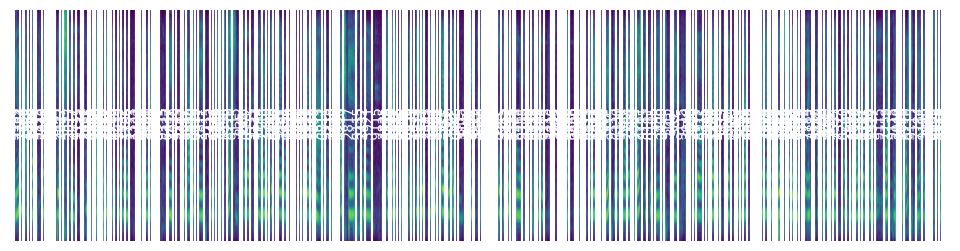

In [25]:
plt.figure(figsize=(12, 3))
plt.subplot(1, 1, 1)
plt.imshow(melspec, aspect="auto", origin="lower")
plt.axis("off")
for start, end, id in zip(starts_merged, ends_merged, ids_merged):
    plt.axvline(start, c="w")
    plt.axvline(end, c="w")
    plt.text(
        (start + end) / 2,
        64,
        str(id.item()),
        rotation=90,
        c="w",
        ha="center",
        va="center",
    )

## Export syllable boundaries to a TextGrid

Writes `starts_merged`, `ends_merged`, and `ids_merged` out to a Praat TextGrid
with a single `syllables` interval tier (start/end time per syllable, like
`item [3]` in `id_5_main_post_test_syllables.TextGrid`, but without the
`words`/`phones` tiers).


In [ ]:
import tgt

# starts_merged / ends_merged are frame indices (20 ms/frame -> 50 frames per second,
# since hop_length=320 at sr=16000). Convert to seconds using the actual sample rate.
frame_rate = sr / 320

syl_tier = tgt.IntervalTier(
    start_time=0.0,
    end_time=ends_merged[-1].item() / frame_rate,
    name="syllables",
)

for start, end, syl_id in zip(starts_merged, ends_merged, ids_merged):
    xmin = start.item() / frame_rate
    xmax = end.item() / frame_rate
    if xmax <= xmin:
        continue  # skip degenerate zero-length intervals
    # leave silence intervals blank, like the "" intervals in the example TextGrid
    label = "" if syl_id.item() == SIL else str(syl_id.item())
    syl_tier.add_interval(tgt.Interval(xmin, xmax, label))

syllable_textgrid = tgt.TextGrid()
syllable_textgrid.add_tier(syl_tier)

# id number for this recording, e.g. "5" for id_5_main_post_test.wav
output_id = "5"
output_path = f"ZeroSyl_{output_id}_syllables.TextGrid"

tgt.write_to_file(syllable_textgrid, output_path, format="long")
print(f"Saved {output_path}")